In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
from scipy.stats import f_oneway

In [4]:
df = pd.read_csv("/content/heart_failure.csv")

In [5]:
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40.0,M,ATA,140.0,289.0,0.0,Normal,172.0,N,0.0,Up,0.0
1,49.0,F,NAP,160.0,180.0,0.0,Normal,156.0,N,1.0,Flat,1.0
2,37.0,M,ATA,130.0,283.0,0.0,ST,98.0,N,0.0,Up,0.0
3,48.0,F,ASY,138.0,214.0,0.0,Normal,108.0,Y,1.5,Flat,1.0
4,54.0,M,NAP,150.0,195.0,0.0,Normal,122.0,N,0.0,Up,0.0


In [6]:
df.tail()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
1234,29.0,F,ATA,120.0,NaN,1.0,LVH,100.0,Y,2.0,Flat,0.0
1235,70.0,M,NAP,150.0,180.0,1.0,ST,180.0,N,3.0,Flat,0.0
1236,60.0,M,ATA,130.0,300.0,1.0,Normal,160.0,N,1.0,Up,1.0
1237,50.0,M,ASY,120.0,300.0,NaN,ST,140.0,N,1.0,Down,0.0
1238,40.0,F,ATA,140.0,250.0,0.0,ST,140.0,Y,2.0,Flat,1.0


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1239 entries, 0 to 1238
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             1230 non-null   float64
 1   Sex             1234 non-null   object 
 2   ChestPainType   1232 non-null   object 
 3   RestingBP       1231 non-null   float64
 4   Cholesterol     1229 non-null   float64
 5   FastingBS       1234 non-null   float64
 6   RestingECG      1234 non-null   object 
 7   MaxHR           1233 non-null   float64
 8   ExerciseAngina  1235 non-null   object 
 9   Oldpeak         1233 non-null   float64
 10  ST_Slope        1232 non-null   object 
 11  HeartDisease    1236 non-null   float64
dtypes: float64(7), object(5)
memory usage: 116.3+ KB


In [8]:
df.shape

(1239, 12)

In [9]:
df.describe()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,1230.000000,1231.000000,1229.000000,1234.000000,1233.000000,1233.000000,1236.000000
mean,51.724390,135.047116,206.729862,0.299028,137.557989,1.054177,0.532362
std,11.355974,21.379940,98.582107,0.461545,27.518915,1.174154,0.500773
min,28.000000,0.000000,0.000000,0.000000,20.000000,-5.000000,0.000000
25%,43.000000,120.000000,180.000000,0.000000,120.000000,0.000000,0.000000
50%,53.000000,130.000000,220.000000,0.000000,140.000000,1.000000,1.000000
75%,60.000000,145.000000,264.000000,1.000000,160.000000,2.000000,1.000000
max,110.000000,351.000000,603.000000,2.000000,398.000000,7.000000,2.000000


In [10]:
df.dropna(inplace = True)

In [11]:
df.isnull().sum()

,0
Age,0
Sex,0
ChestPainType,0
RestingBP,0
Cholesterol,0
FastingBS,0
RestingECG,0
MaxHR,0
ExerciseAngina,0
Oldpeak,0


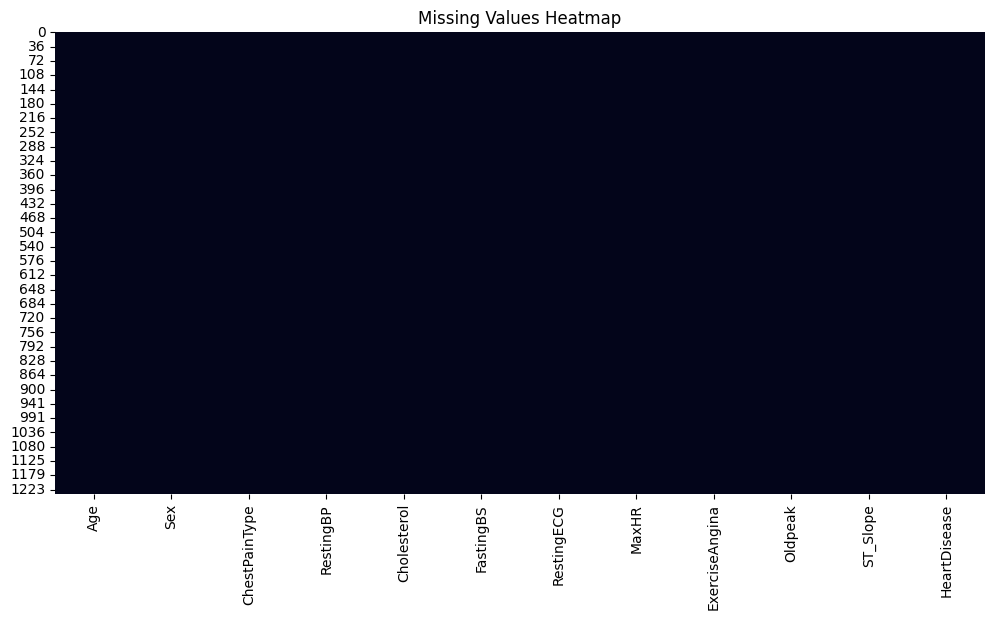

In [12]:
plt.figure(figsize=(12,6))
sns.heatmap(df.isnull(), cbar=False)
plt.title("Missing Values Heatmap")
plt.show()

In [13]:
df.duplicated().sum()

np.int64(0)

In [14]:
for col in df.columns:
  print(f"Unique values in column '{col} : ")
  print(df[col].unique())
  print("-"*30)

Unique values in column 'Age : 
[ 40.  49.  37.  48.  54.  39.  45.  58.  42.  38.  43.  60.  36.  44.
  53.  52.  51.  56.  41.  32.  65.  35.  59.  50.  47.  31.  46.  57.
  55.  63.  66.  34.  33.  61.  29.  62.  28.  30.  74.  68.  72.  64.
  69.  67.  73.  70.  77.  75.  76.  71. 110.]
------------------------------
Unique values in column 'Sex : 
['M' 'F' 'unk' '??' ' ']
------------------------------
Unique values in column 'ChestPainType : 
['ATA' 'NAP' 'ASY' 'TA' 'unk' ' ']
------------------------------
Unique values in column 'RestingBP : 
[140. 160. 130. 138. 150. 120. 110. 136. 115. 100. 124. 113. 125. 145.
 112. 132. 118. 170. 142. 190. 135. 180. 108. 155. 128. 106.  92. 200.
 122.  98. 105. 133.  95.  80. 137. 185. 165. 126. 152. 116.   0. 144.
 154. 134. 104. 139. 131. 141. 178. 146. 158. 123. 102.  96. 143. 172.
 156. 114. 127. 101. 174.  94. 148. 117. 192. 129. 164. 313. 351.]
------------------------------
Unique values in column 'Cholesterol : 
[289. 180. 283. 214. 

In [15]:
suspects = ['?', '??', 'NA', 'N/A', 'na', 'None', 'null', 'Null', 'Unknown', 'UNK', '-', '--', ' ', 'Nan', 'XXX', 'unk', 9999, -9999]
for val in suspects:
  print(f"{val}:")
  print((df == val).sum())

?:
Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64
??:
Age               0
Sex               1
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        1
MaxHR             0
ExerciseAngina    1
Oldpeak           0
ST_Slope          1
HeartDisease      0
dtype: int64
NA:
Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64
N/A:
Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
Heart

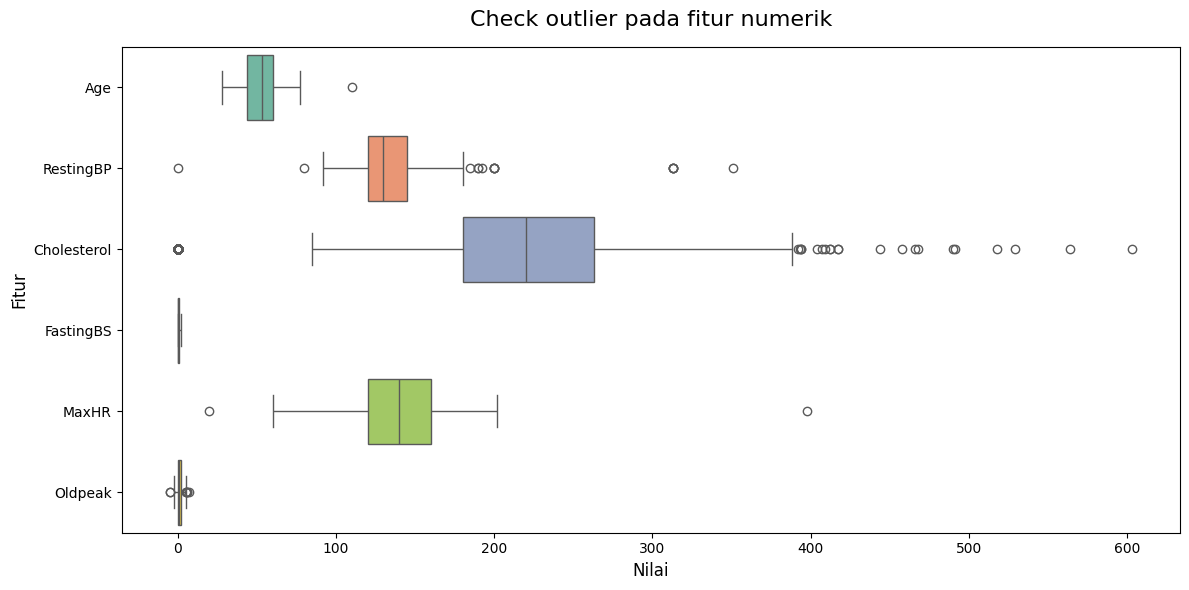

In [16]:
num_cols = ['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak']

plt.figure(figsize=(12,6))

sns.boxplot(data=df[num_cols],orient = 'h', palette='Set2')

plt.title('Check outlier pada fitur numerik', fontsize=16, pad=15)
plt.xlabel('Nilai', fontsize=12)
plt.ylabel('Fitur', fontsize=12)

plt.tight_layout()
plt.show()

/tmp/ipykernel_2749/743136191.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='HeartDisease', palette='viridis')


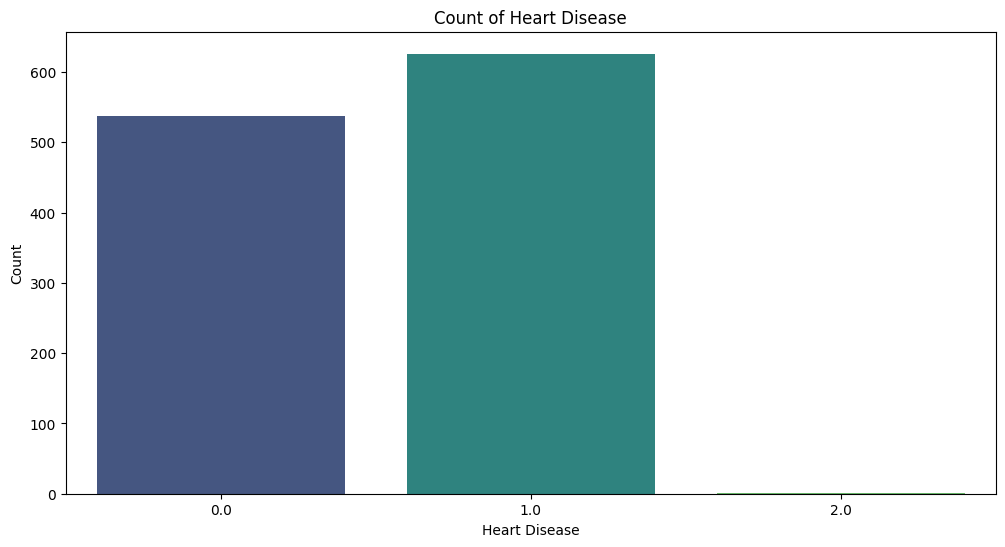

In [17]:
plt.figure(figsize=(12,6))
sns.countplot(data=df, x='HeartDisease', palette='viridis')
plt.title('Count of Heart Disease')
plt.xlabel('Heart Disease')
plt.ylabel('Count')
plt.show()

array([[<Axes: title={'center': 'Age'}>,
        <Axes: title={'center': 'RestingBP'}>],
       [<Axes: title={'center': 'Cholesterol'}>,
        <Axes: title={'center': 'FastingBS'}>],
       [<Axes: title={'center': 'MaxHR'}>,
        <Axes: title={'center': 'Oldpeak'}>]], dtype=object)

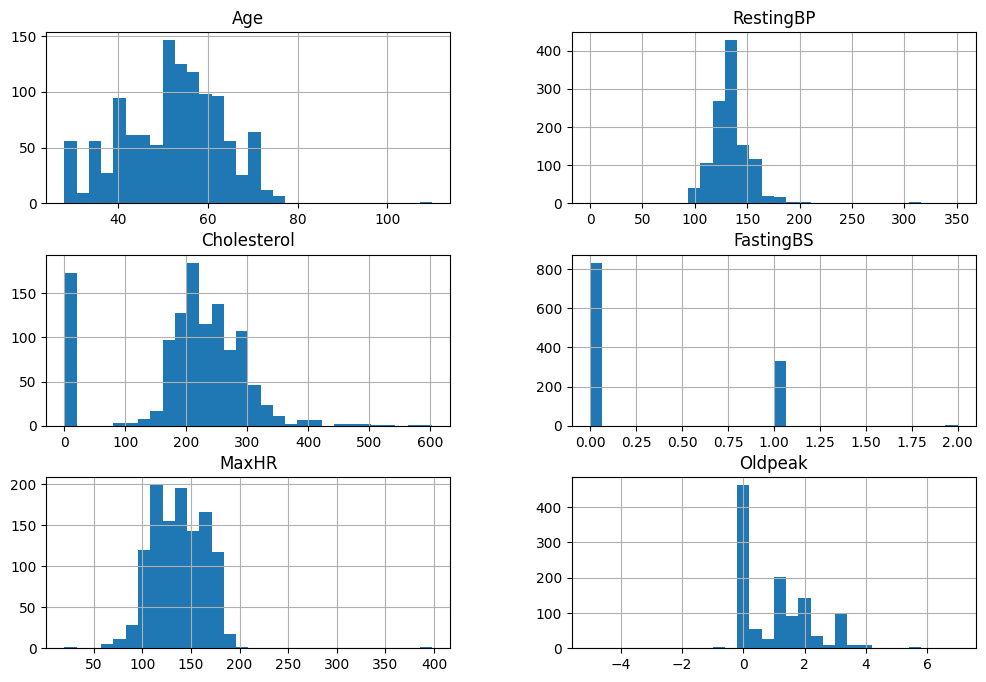

In [18]:
df[num_cols].hist(figsize=(12, 8), bins=30)


Sex unique values: 5
Sex
M      838
F      323
unk      1
??       1
         1
Name: count, dtype: int64

ChestPainType unique values: 6
ChestPainType
ASY    558
NAP    255
ATA    250
TA      99
unk      1
         1
Name: count, dtype: int64

FastingBS unique values: 3
FastingBS
0.0    832
1.0    330
2.0      2
Name: count, dtype: int64

RestingECG unique values: 5
RestingECG
Normal    636
ST        263
LVH       263
??          1
            1
Name: count, dtype: int64

ExerciseAngina unique values: 6
ExerciseAngina
N      671
Y      489
??       1
         1
XXX      1
unk      1
Name: count, dtype: int64

ST_Slope unique values: 6
ST_Slope
Flat    540
Up      474
Down    147
XXX       1
??        1
          1
Name: count, dtype: int64

HeartDisease unique values: 3
HeartDisease
1.0    626
0.0    537
2.0      1
Name: count, dtype: int64


/tmp/ipykernel_2749/4069029853.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=col,order=df[col].value_counts().index, palette='viridis')


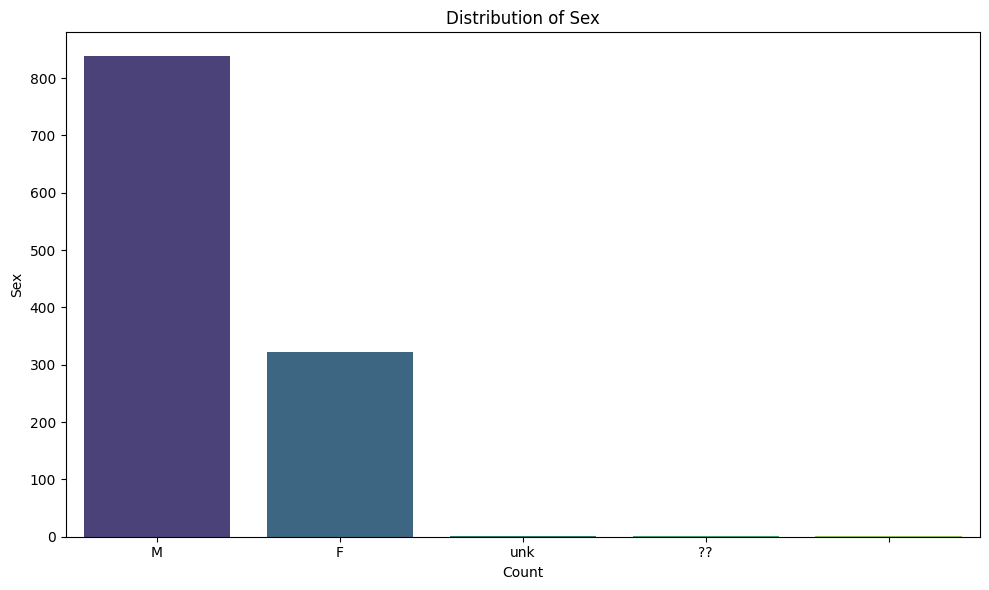

/tmp/ipykernel_2749/4069029853.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=col,order=df[col].value_counts().index, palette='viridis')


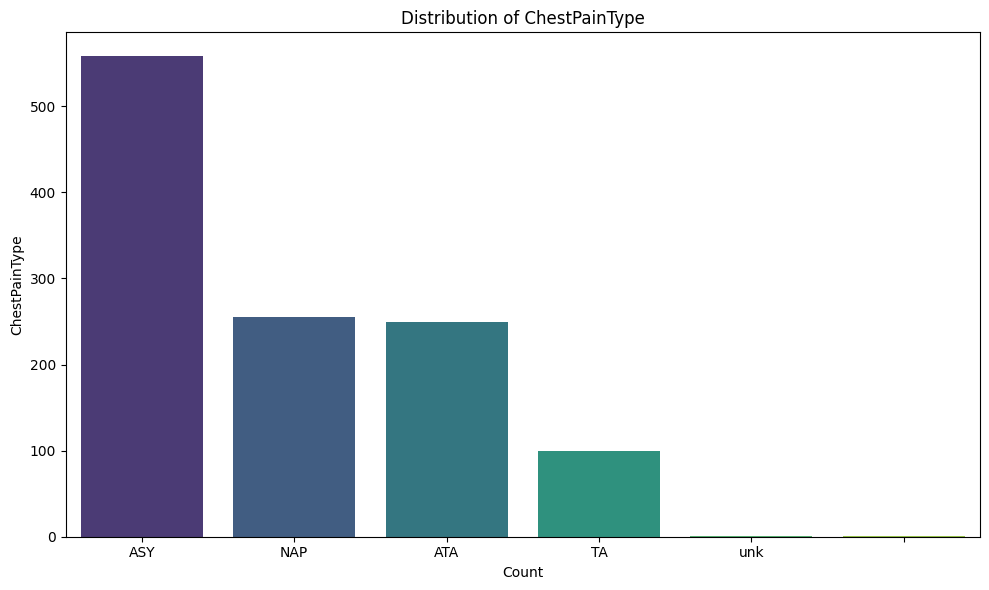

/tmp/ipykernel_2749/4069029853.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=col,order=df[col].value_counts().index, palette='viridis')


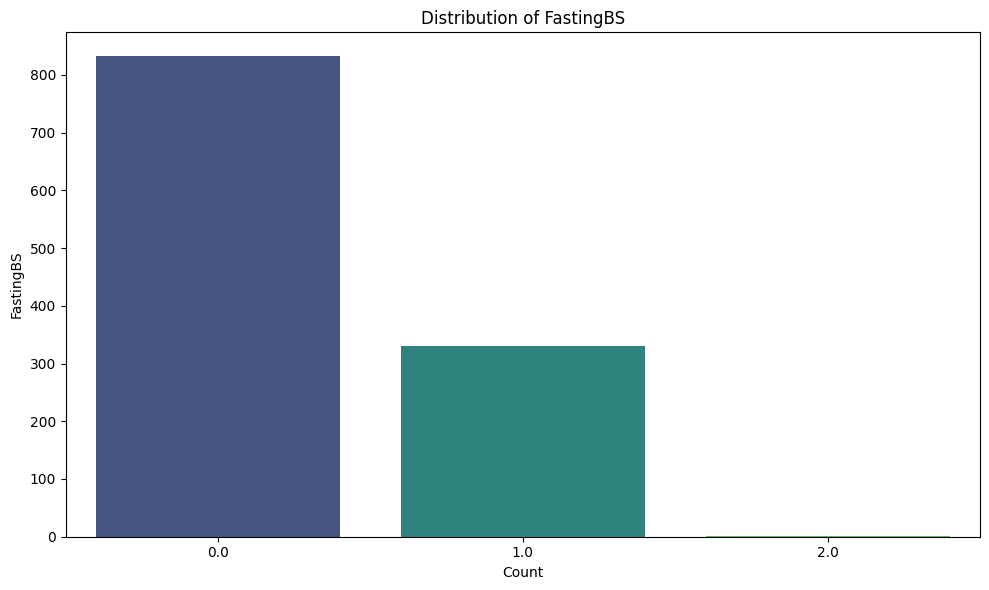

/tmp/ipykernel_2749/4069029853.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=col,order=df[col].value_counts().index, palette='viridis')


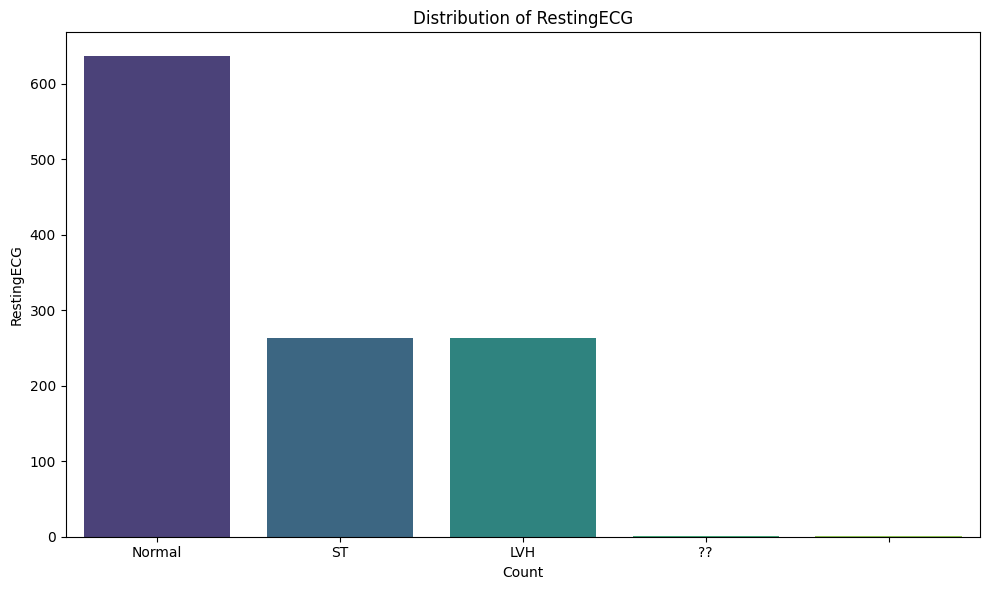

/tmp/ipykernel_2749/4069029853.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=col,order=df[col].value_counts().index, palette='viridis')


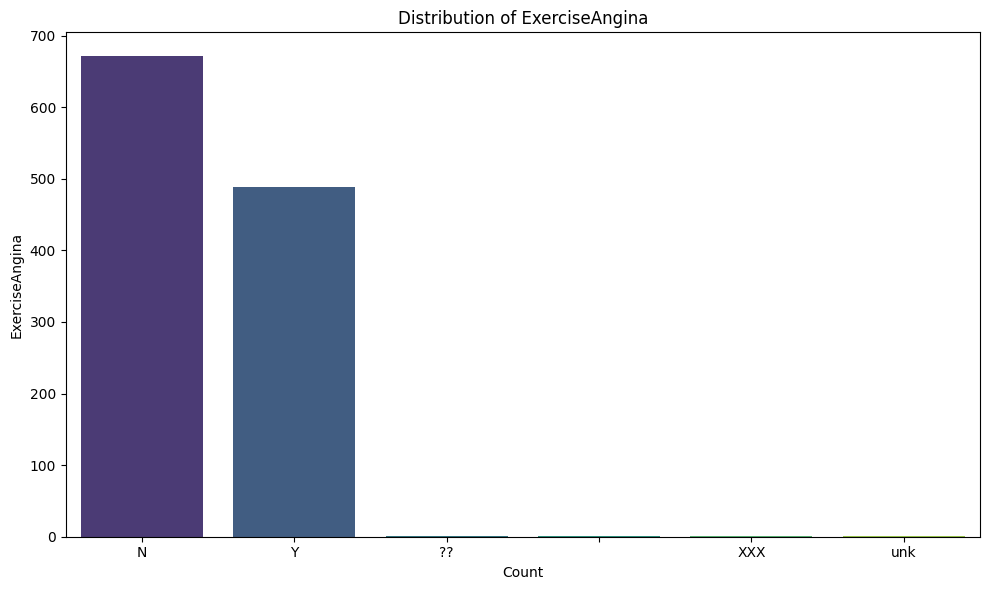

/tmp/ipykernel_2749/4069029853.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=col,order=df[col].value_counts().index, palette='viridis')


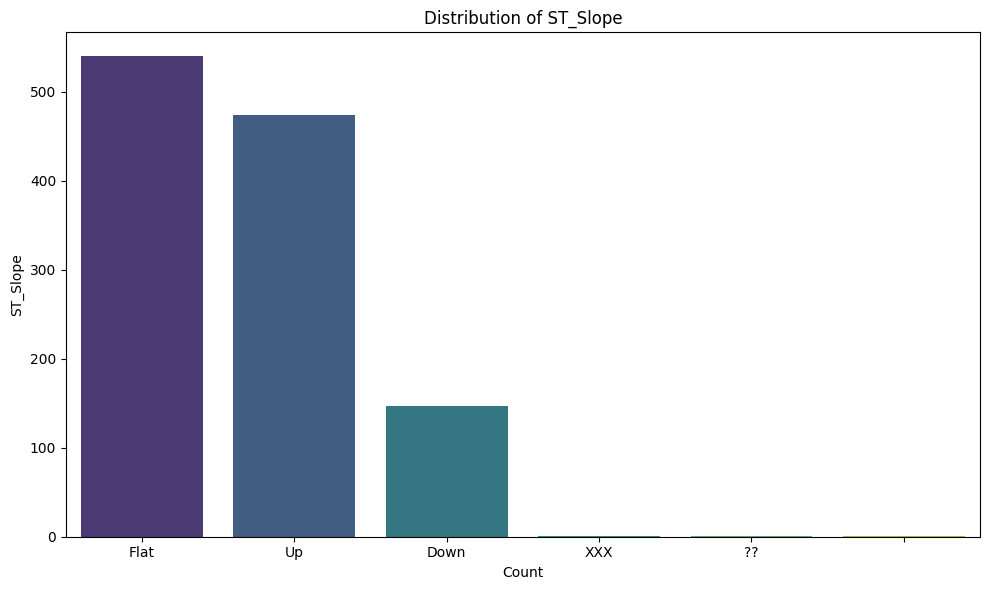

/tmp/ipykernel_2749/4069029853.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=col,order=df[col].value_counts().index, palette='viridis')


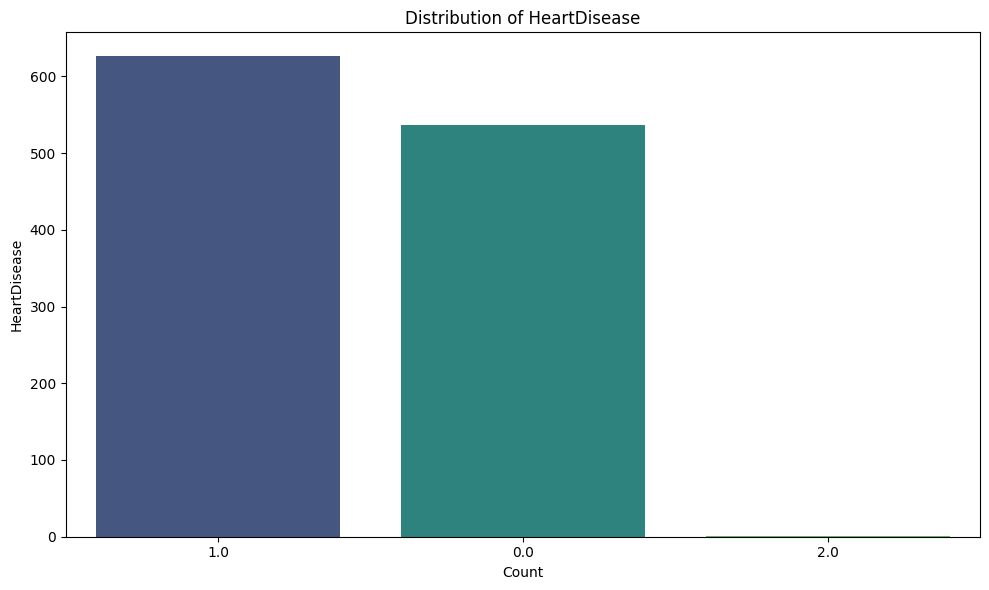

Skipping plot for 'HeartDisease due to high number of unique values (3)


In [19]:
cat_cols = ['Sex', 'ChestPainType', 'FastingBS', 'RestingECG', 'ExerciseAngina', 'ST_Slope', 'HeartDisease']

for col in cat_cols:
  print(f"\n{col} unique values:", df [col].nunique())
  print(df[col].value_counts().head(10))

for col in cat_cols:
  if df[col].nunique() < 50:
    plt.figure(figsize=(10, 6))
    sns.countplot(data=df, x=col,order=df[col].value_counts().index, palette='viridis')
    plt.title(f'Distribution of {col}')
    plt.xlabel('Count')
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()
else:
      print(f"Skipping plot for '{col} due to high number of unique values ({df[col].nunique()})")

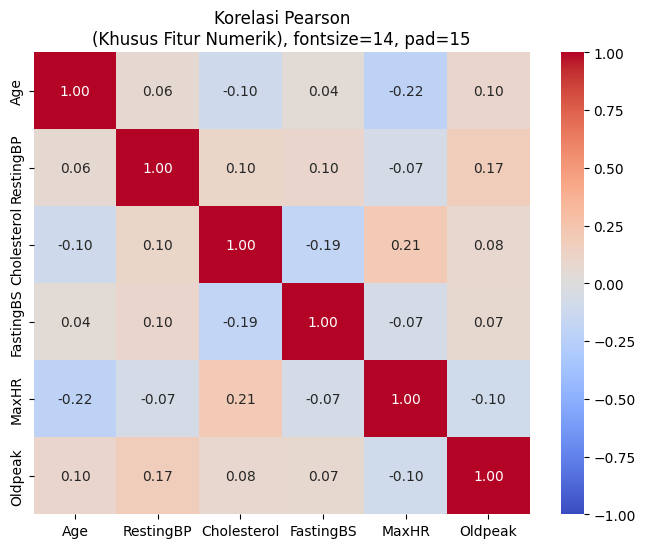

In [20]:
plt.figure(figsize=(8,6))
pearson_matrix = df[num_cols].corr(method='pearson')
sns.heatmap(pearson_matrix, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)
plt.title("Korelasi Pearson\n(Khusus Fitur Numerik), fontsize=14, pad=15")
plt.show()

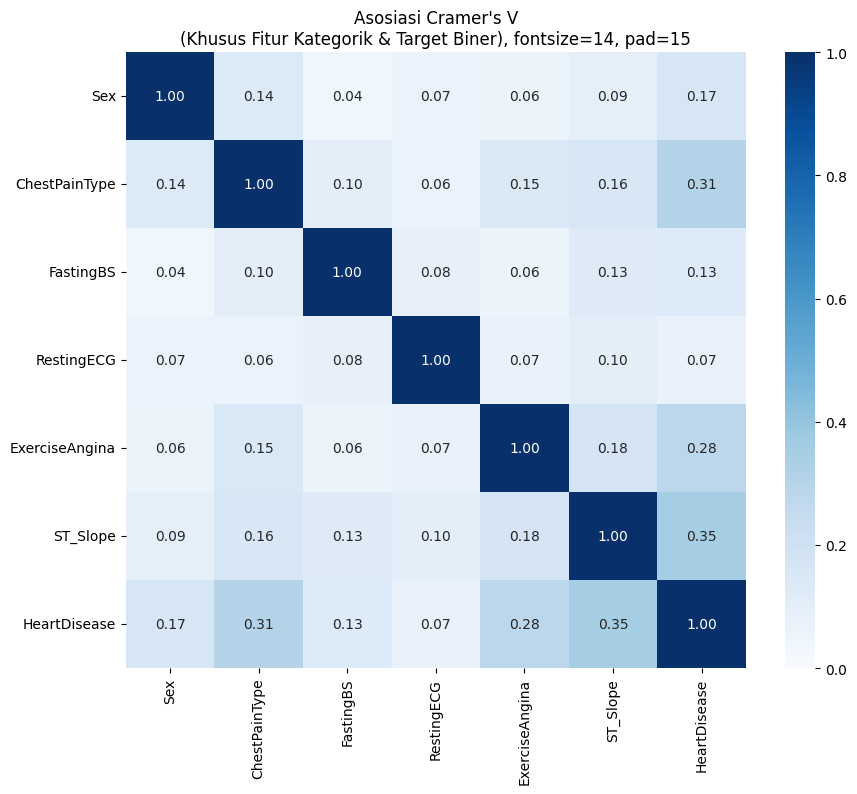

In [21]:
def cramers_v(x,y):
  confusion_matrix = pd.crosstab(x,y)
  chi2 = chi2_contingency(confusion_matrix)[0]
  n = confusion_matrix.sum().sum()
  r, c = confusion_matrix.shape
  if min(r-1, c-1) == 0:
    return 0.0
  return np.sqrt((chi2/n) / min(r-1, c-1))

cramer_matrix = pd.DataFrame(index=cat_cols, columns=cat_cols)
for col1 in cat_cols:
  for col2 in cat_cols:
    cramer_matrix.loc[col1,col2] = cramers_v(df[col1], df[col2])

cramer_matrix = cramer_matrix.astype('float')

plt.figure(figsize=(10,8))
sns.heatmap(cramer_matrix, annot=True, cmap='Blues', fmt='.2f', vmin=0, vmax=1)
plt.title("Asosiasi Cramer's V\n(Khusus Fitur Kategorik & Target Biner), fontsize=14, pad=15")
plt.show()

/tmp/ipykernel_2749/1976806487.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='HeartDisease', y=col, data=df, ax=axes[i], palette='Set2')
/tmp/ipykernel_2749/1976806487.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='HeartDisease', y=col, data=df, ax=axes[i], palette='Set2')
/tmp/ipykernel_2749/1976806487.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='HeartDisease', y=col, data=df, ax=axes[i], palette='Set2')
/tmp/ipykernel_2749/1976806487.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated an

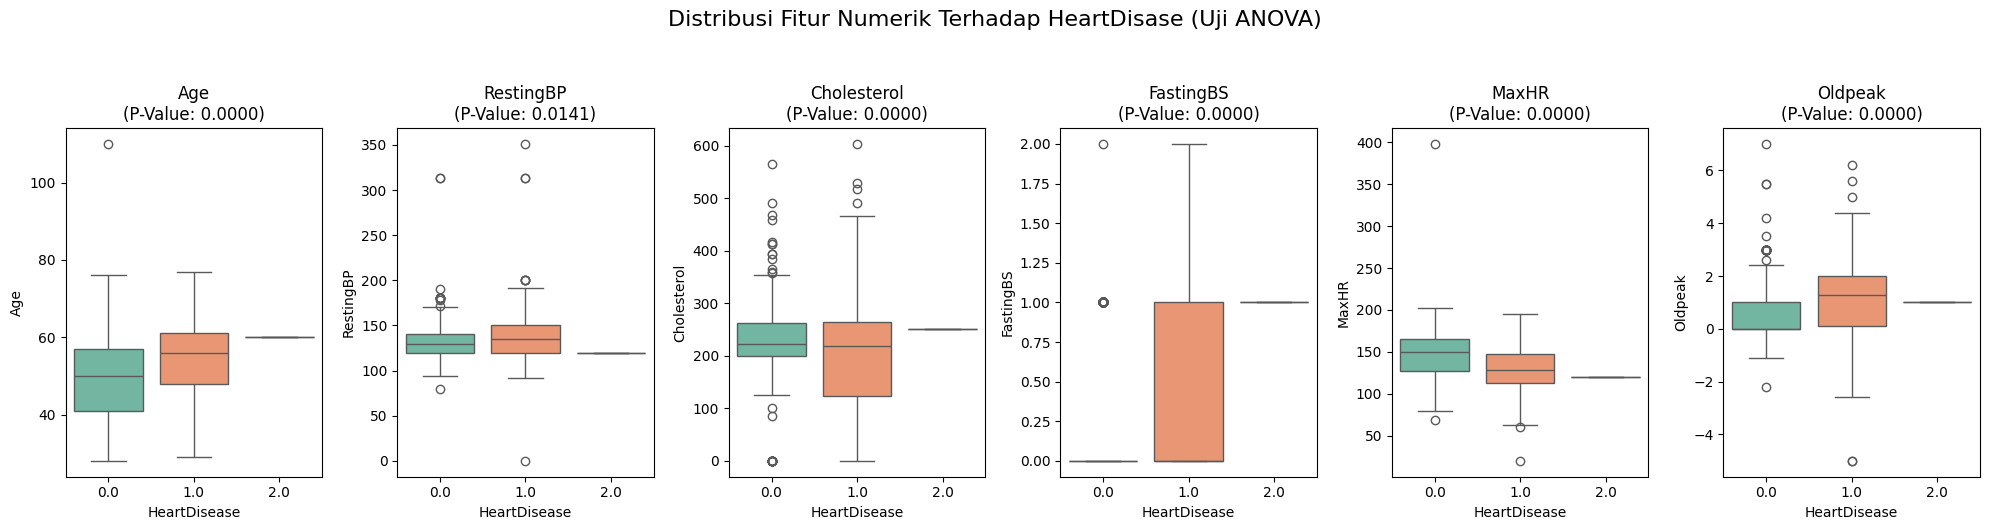

In [22]:
fig, axes = plt.subplots(1, len(num_cols), figsize=(20,5))
fig.suptitle('Distribusi Fitur Numerik Terhadap HeartDisase (Uji ANOVA)', fontsize=16, y=1.05)

for i, col in enumerate(num_cols):
  sns.boxplot(x='HeartDisease', y=col, data=df, ax=axes[i], palette='Set2')
  group0 = df[df['HeartDisease'] == 0][col].dropna()
  group1 = df[df['HeartDisease'] == 1][col].dropna()

  if len(group0) > 0 and len(group1) > 0:
    f_stat, p_val = f_oneway(group0, group1)
    axes[i].set_title(f"{col}\n(P-Value: {p_val:.4f})")
  else:
    axes[i].set_title(col)

plt.tight_layout()
plt.show()

In [23]:
from sklearn.model_selection import train_test_split
from sklearn. preprocessing import StandardScaler, MinMaxScaler, OrdinalEncoder, OneHotEncoder, LabelEncoder

df = pd.read_csv('/content/heart_failure.csv')

In [24]:
df.dropna(inplace = True)

In [25]:
df.dropna(axis=1, inplace=True)
# atau
df.dropna(axis='columns', inplace=True)

In [26]:
df['Age'].fillna(df['Age'].mean(), inplace=True)
df.isnull().sum()

/tmp/ipykernel_2749/3252030817.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Age'].fillna(df['Age'].mean(), inplace=True)


,0
Age,0
Sex,0
ChestPainType,0
RestingBP,0
Cholesterol,0
FastingBS,0
RestingECG,0
MaxHR,0
ExerciseAngina,0
Oldpeak,0


In [27]:
df['RestingBP']. fillna(df['RestingBP'].median(), inplace=True)
df.isna().sum()

/tmp/ipykernel_2749/344134683.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['RestingBP']. fillna(df['RestingBP'].median(), inplace=True)


,0
Age,0
Sex,0
ChestPainType,0
RestingBP,0
Cholesterol,0
FastingBS,0
RestingECG,0
MaxHR,0
ExerciseAngina,0
Oldpeak,0


In [28]:
df['ChestPainType'].fillna(df['ChestPainType'].mode()[0], inplace=True)
df.isna().sum()

/tmp/ipykernel_2749/2024835590.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['ChestPainType'].fillna(df['ChestPainType'].mode()[0], inplace=True)


,0
Age,0
Sex,0
ChestPainType,0
RestingBP,0
Cholesterol,0
FastingBS,0
RestingECG,0
MaxHR,0
ExerciseAngina,0
Oldpeak,0


In [29]:
df.duplicated().sum()
df.drop_duplicates()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40.0,M,ATA,140.0,289.0,0.0,Normal,172.0,N,0.0,Up,0.0
1,49.0,F,NAP,160.0,180.0,0.0,Normal,156.0,N,1.0,Flat,1.0
2,37.0,M,ATA,130.0,283.0,0.0,ST,98.0,N,0.0,Up,0.0
3,48.0,F,ASY,138.0,214.0,0.0,Normal,108.0,Y,1.5,Flat,1.0
4,54.0,M,NAP,150.0,195.0,0.0,Normal,122.0,N,0.0,Up,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...
1232,29.0,F,ATA,160.0,220.0,1.0,LVH,100.0,N,3.0,Up,1.0
1233,50.0,F,NAP,130.0,250.0,0.0,ST,160.0,Y,3.0,Down,1.0
1235,70.0,M,NAP,150.0,180.0,1.0,ST,180.0,N,3.0,Flat,0.0
1236,60.0,M,ATA,130.0,300.0,1.0,Normal,160.0,N,1.0,Up,1.0


In [30]:
#df.drop_duplicates(subset=['nama', 'email'], inplace=True)

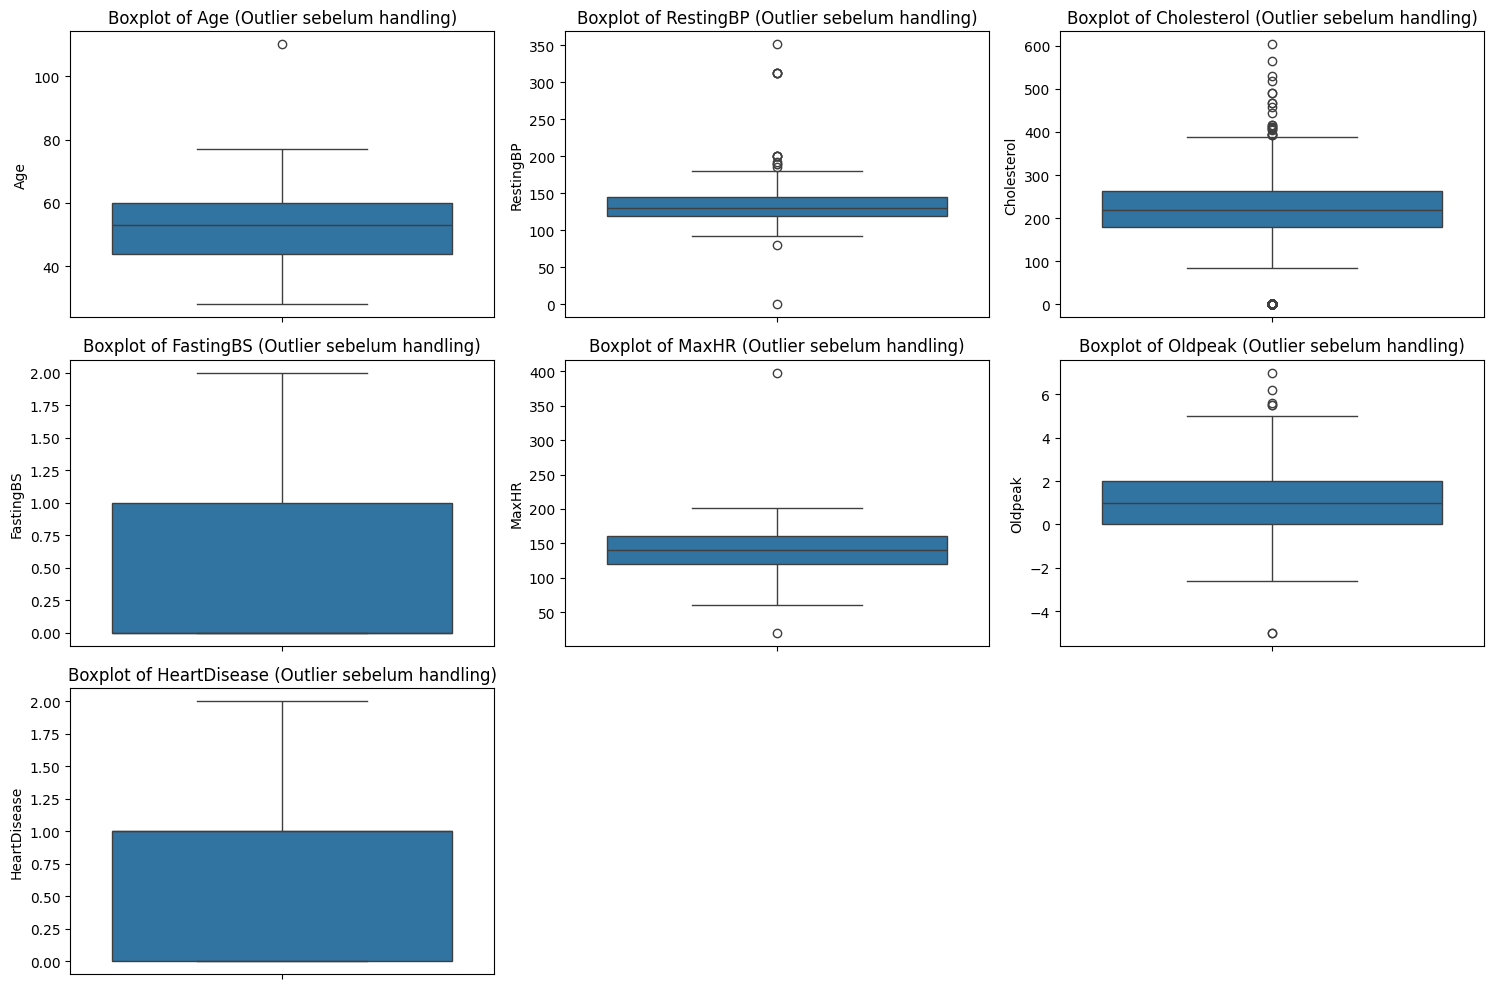

In [31]:
numerical_cols = df.select_dtypes(include=[np.number]).columns

plt.figure(figsize=(15, 10))
for i, col in enumerate(numerical_cols, 1):
  plt.subplot(3, 3, i)
  sns. boxplot(y=df [col])
  plt.title(f'Boxplot of {col} (Outlier sebelum handling)')

plt.tight_layout()
plt.show()

In [32]:
outlier_cols = ['RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']

for col in outlier_cols:
  Q1 = df[col].quantile(0.25)
  Q3 = df[col].quantile(0.75)
  IQR = Q3 - Q1

  lower_bound = Q1 - 1.5 * IQR
  upper_bound = Q3 + 1.5 * IQR

  df = df[(df[col] >= lower_bound) & (df[col] <= upper_bound)]

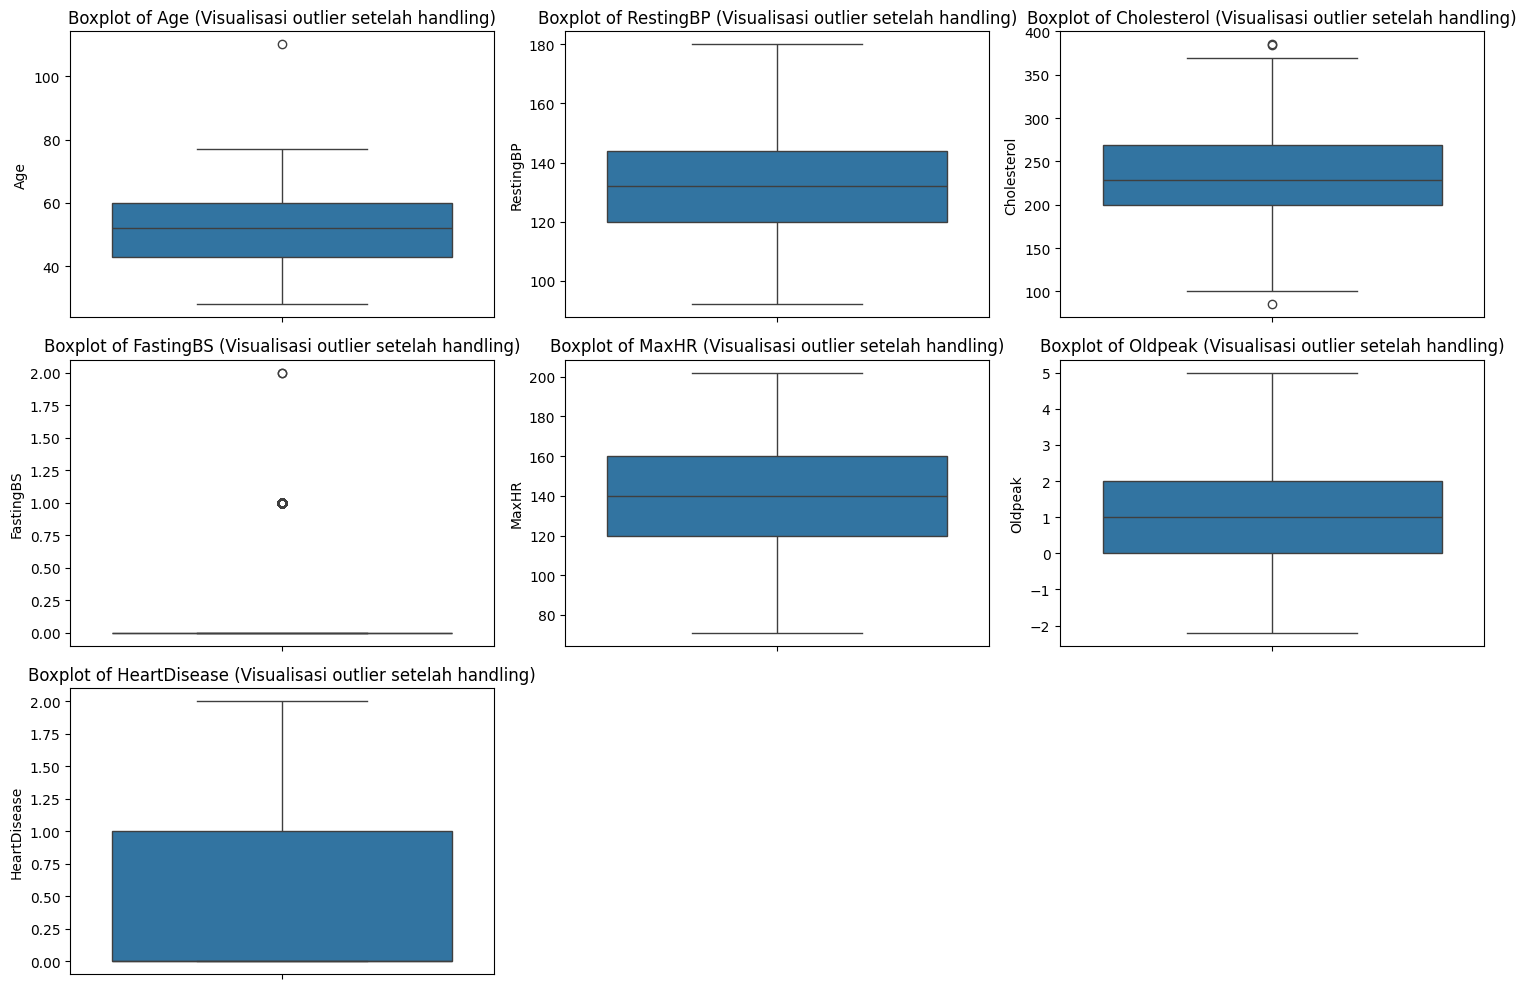

In [33]:
numerical_cols = df.select_dtypes(include=[np.number]).columns

plt.figure(figsize=(15, 10))
for i, col in enumerate(numerical_cols, 1):
  plt.subplot(3, 3, i)
  sns. boxplot(y=df [col])
  plt.title(f'Boxplot of {col} (Visualisasi outlier setelah handling)')

plt.tight_layout()
plt.show()

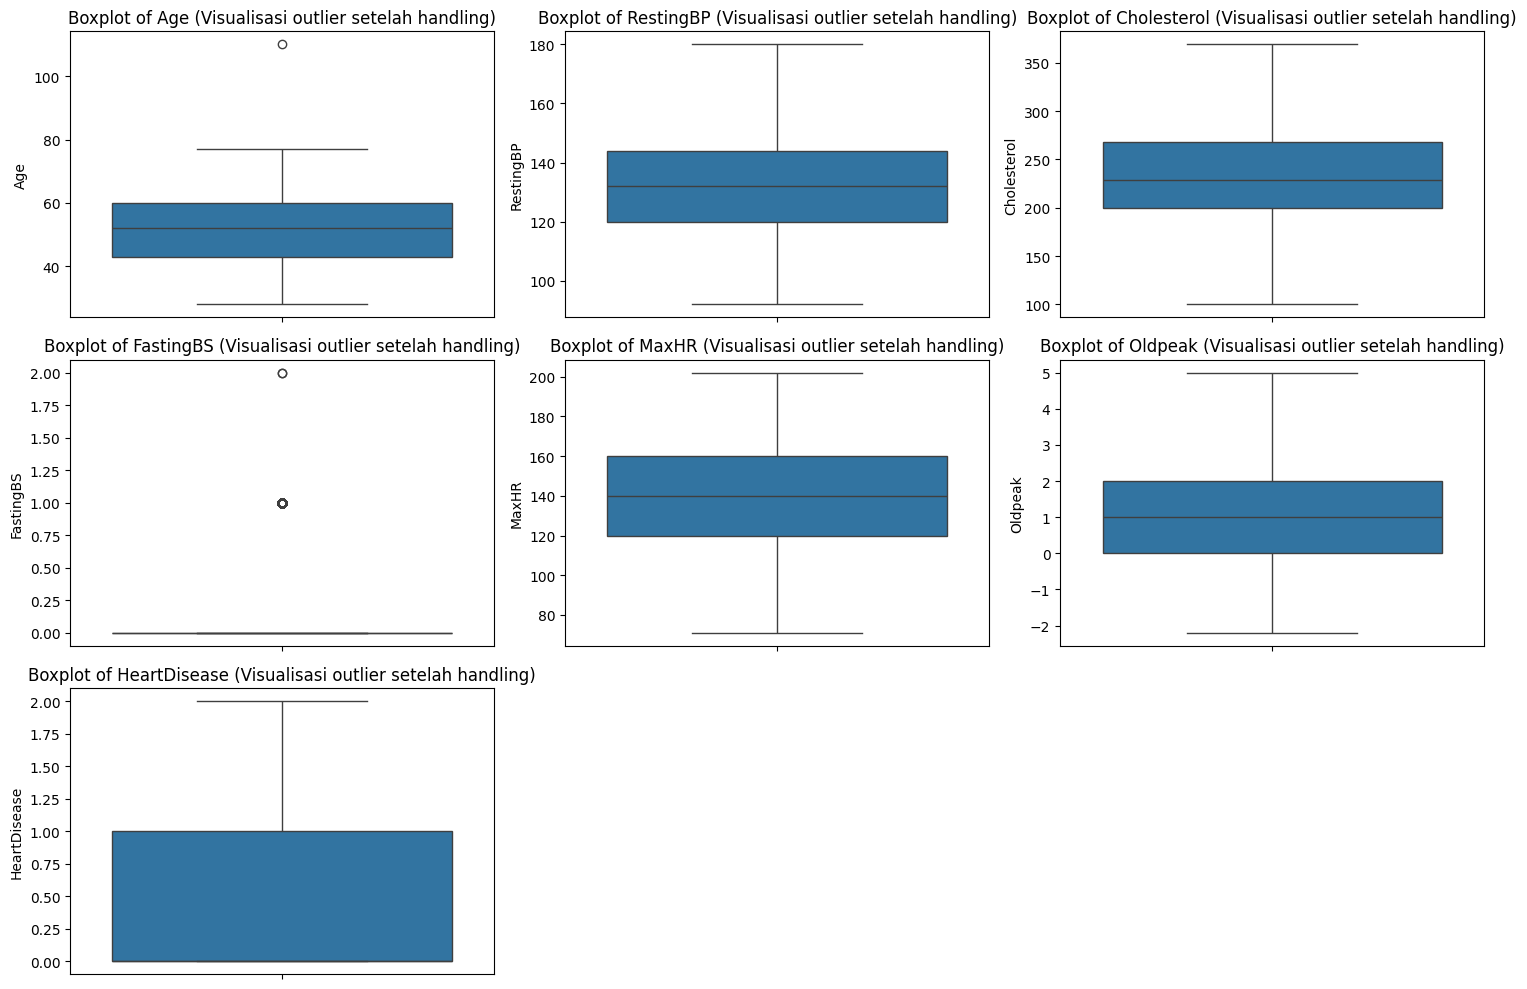

In [34]:
#main code
outlier_cols = [ 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']

for col in outlier_cols:
  Q1 = df[col].quantile(0.25)
  Q3 = df[col].quantile(0.75)
  IQR = Q3 - Q1

  lower_bound = Q1 - 1.5 * IQR
  upper_bound = Q3 + 1.5 * IQR

  median_value = df[col].median( )

  #handling outlier dengan median
  df [col] = df[col].apply(lambda x: median_value if x < lower_bound or x > upper_bound else x)

#visual hasil
numerical_cols = df.select_dtypes(include=[np.number]).columns

plt.figure(figsize=(15, 10))
for i, col in enumerate(numerical_cols, 1):
  plt.subplot(3, 3, i)
  sns. boxplot(y=df [col])
  plt.title(f'Boxplot of {col} (Visualisasi outlier setelah handling)')

plt.tight_layout()
plt.show()

In [35]:
print(df['Sex'].nunique())
print(df['Sex'].unique())

df["Sex"].replace(" ", np.nan, inplace=True)
df["Sex"].replace("unk", np.nan, inplace=True)
df["Sex"]. replace("??", np.nan, inplace=True)

5
['M' 'F' 'unk' '??' ' ']


/tmp/ipykernel_2749/1609366495.py:4: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["Sex"].replace(" ", np.nan, inplace=True)
/tmp/ipykernel_2749/1609366495.py:5: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try usin

In [36]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# Ensure that the 'HeartDisease' column does not contain any class with only one member
# In previous analysis, HeartDisease = 2.0 was identified as a rare class with one instance.
# We remove it to enable stratification.
df = df[df['HeartDisease'] != 2.0]

X = df.drop("HeartDisease", axis=1)
y = df["HeartDisease"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

le = LabelEncoder()

y_train = le.fit_transform(y_train)
y_test = le.transform(y_test)

print("1. Daftar kelas asli yang dipetakan (le.classes_):")
print(le.classes_)

print("\n2. Contoh hasil y_train setelah encoding (10 data pertama):")
print(y_train[:10])

print("\n3. Contoh hasil y_test setelah encoding (10 data pertama):")
print(y_test[:10])

1. Daftar kelas asli yang dipetakan (le.classes_):
[0. 1.]

2. Contoh hasil y_train setelah encoding (10 data pertama):
[0 0 1 1 1 0 1 1 1 0]

3. Contoh hasil y_test setelah encoding (10 data pertama):
[0 1 0 0 0 0 1 1 1 0]


In [37]:
binomial_cols = ['Sex', 'ExerciseAngina', 'ChestPainType', 'RestingECG', 'ST_Slope']
for col in binomial_cols:
  oe = OrdinalEncoder()
  df [col] = oe.fit_transform(df[[col]])
  print("Berhasil melakukan Ordinal Encoding!")
print("\n5 baris pertama dari kolom-kolom yang sudah di-encode:")
display(df[binomial_cols].head())

Berhasil melakukan Ordinal Encoding!
Berhasil melakukan Ordinal Encoding!
Berhasil melakukan Ordinal Encoding!
Berhasil melakukan Ordinal Encoding!
Berhasil melakukan Ordinal Encoding!

5 baris pertama dari kolom-kolom yang sudah di-encode:


,Sex,ExerciseAngina,ChestPainType,RestingECG,ST_Slope
0,1.0,2.0,2.0,3.0,4.0
1,0.0,2.0,3.0,3.0,3.0
2,1.0,2.0,2.0,4.0,4.0
3,0.0,4.0,1.0,3.0,3.0
4,1.0,2.0,3.0,3.0,4.0


In [38]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

cols = ["ChestPainType", "RestingECG"]

ct = ColumnTransformer(
    transformers=[
        ("ohe", OneHotEncoder(sparse_output=False, handle_unknown="ignore"), cols)
    ],
    remainder='passthrough'
)

X_train_encode = ct.fit_transform(X_train)
X_test_encode = ct.transform(X_test)

# ambil nama kolom OHE
ohe_cols = ct.named_transformers_["ohe"].get_feature_names_out(cols)

# ambil kolom lain (yang tidak di-OHE)
other_cols = [col for col in X_train.columns if col not in cols]

# gabungkan nama kolom
all_cols = list(ohe_cols) + other_cols

# convert ke DataFrame
X_train_encode_df = pd.DataFrame(
    X_train_encode,
    columns=all_cols,
    index=X_train.index
)

X_test_encode_df = pd.DataFrame(
    X_test_encode,
    columns=all_cols,
    index=X_test.index
)

# lihat hasil
X_train_encode_df.head()

,ChestPainType_ASY,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,ChestPainType_unk,RestingECG_,RestingECG_??,RestingECG_LVH,RestingECG_Normal,RestingECG_ST,Age,Sex,RestingBP,Cholesterol,FastingBS,MaxHR,ExerciseAngina,Oldpeak,ST_Slope
1177,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,29.0,M,150.0,200.0,1.0,120.0,N,1.0,Down
1211,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,40.0,F,140.0,200.0,0.0,120.0,N,1.0,Flat
448,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,63.0,M,160.0,230.0,1.0,105.0,Y,1.0,Flat
1109,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,29.0,F,140.0,180.0,0.0,140.0,Y,2.0,Down
612,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,55.0,M,122.0,223.0,1.0,100.0,N,0.0,Flat


In [39]:
from sklearn.preprocessing import StandardScaler, OrdinalEncoder

# 1. Pilih kolom numerik dan tangani missing values
numeric_cols = ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']
df_num = df[numeric_cols].copy()
df_num = df_num.fillna(df_num.median())

# 2. Terapkan StandardScaler
scaler_std = StandardScaler()
df_standardized = pd.DataFrame(
    scaler_std.fit_transform(df_num),
    columns=numeric_cols
)

print("Hasil StandardScaler (Mean = 0, Std = 1):")
display(df_standardized.head())

Hasil StandardScaler (Mean = 0, Std = 1):


,Age,RestingBP,Cholesterol,MaxHR,Oldpeak
0,-1.002773,0.347790,1.132692,1.240874,-0.942715
1,-0.211402,1.576271,-1.198010,0.613106,-0.041276
2,-1.266563,-0.266451,1.004396,-1.662552,-0.942715
3,-0.299333,0.224941,-0.471002,-1.270197,0.409443
4,0.228248,0.962030,-0.877271,-0.720900,-0.942715


In [40]:
from sklearn.preprocessing import MinMaxScaler

# 1. Pilih kolom numerik dan tangani missing values
numeric_cols = ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']
df_num = df[numeric_cols].copy()
df_num = df_num.fillna(df_num.median())

# 2. Terapkan MinMaxScaler
scaler_minmax = MinMaxScaler()
df_minmax = pd.DataFrame(
    scaler_minmax.fit_transform(df_num),
    columns=numeric_cols
)

print("Hasil MinMaxScaler (Rentang 0 - 1):")
display(df_minmax.head())

Hasil MinMaxScaler (Rentang 0 - 1):


,Age,RestingBP,Cholesterol,MaxHR,Oldpeak
0,0.146341,0.545455,0.702602,0.770992,0.305556
1,0.256098,0.772727,0.297398,0.648855,0.444444
2,0.109756,0.431818,0.680297,0.206107,0.305556
3,0.243902,0.522727,0.423792,0.282443,0.513889
4,0.317073,0.659091,0.353160,0.389313,0.305556


Pertemuan 4

In [41]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from imblearn.over_sampling import SMOTE
import matplotlib.pyplot as plt
import pandas as pd

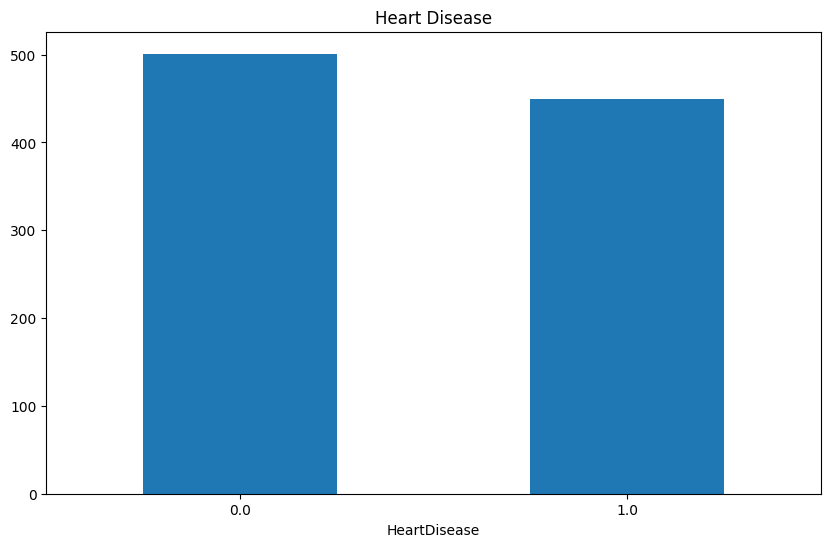

In [42]:
df['HeartDisease'].value_counts().plot(kind='bar', figsize=(10, 6))

plt.title('Heart Disease')
plt.xticks(rotation=0)
plt.show()

In [43]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from imblearn.over_sampling import SMOTE
import matplotlib.pyplot as plt
import pandas as pd

In [44]:
X = df.drop('HeartDisease', axis=1)
y = df['HeartDisease']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [45]:
# Deteksi semua kolom non-numerik (object, category, atau string) di X_train
cat_cols = X_train.select_dtypes(exclude=[np.number]).columns.tolist()

# Lakukan One-Hot Encoding pada kolom-kolom kategorikal tersebut
for col in cat_cols:
    ohe = OneHotEncoder(sparse_output=False, handle_unknown='ignore')

    # Pastikan data diubah ke string terlebih dahulu untuk menghindari error tipe data campuran
    train_encoded = ohe.fit_transform(X_train[[col]].astype(str))
    test_encoded = ohe.transform(X_test[[col]].astype(str))

    # Beri nama kolom baru sesuai kategori
    new_cols = [f"{col}_{cat}" for cat in ohe.categories_[0]]

    # Ubah menjadi DataFrame
    train_df_encoded = pd.DataFrame(train_encoded, columns=new_cols, index=X_train.index)
    test_df_encoded = pd.DataFrame(test_encoded, columns=new_cols, index=X_test.index)

    # Gantikan kolom lama dengan kolom hasil encoding
    X_train = pd.concat([X_train.drop(columns=[col]), train_df_encoded], axis=1)
    X_test = pd.concat([X_test.drop(columns=[col]), test_df_encoded], axis=1)

print("Kolom yang tersisa di X_train:", X_train.dtypes.unique())
print("Apakah masih ada kolom string/object?", X_train.select_dtypes(exclude=[np.number]).columns.tolist())

Kolom yang tersisa di X_train: [dtype('float64')]
Apakah masih ada kolom string/object? []


In [46]:
# Pastikan semua kolom kategorik yang tersisa di-encode terlebih dahulu secara otomatis
X_train_clean = pd.get_dummies(X_train, drop_first=True)
X_test_clean = pd.get_dummies(X_test, drop_first=True)

# Selaraskan kolom antara train dan test agar memiliki kolom yang persis sama
X_train_clean, X_test_clean = X_train_clean.align(X_test_clean, join='left', axis=1, fill_value=0)

# Lakukan scaling dengan StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_clean)
X_test_scaled = scaler.transform(X_test_clean)

print("Scaling berhasil dilakukan! Ukuran data X_train_scaled:", X_train_scaled.shape)

Scaling berhasil dilakukan! Ukuran data X_train_scaled: (760, 11)


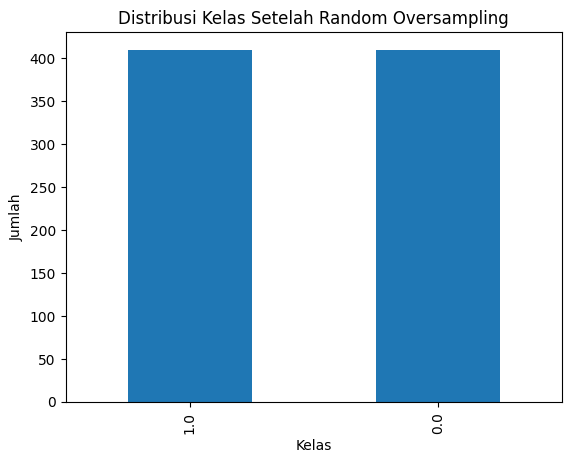

In [47]:
from sklearn.impute import SimpleImputer

# Impute NaN values in X_train_scaled before applying SMOTE
# Using median strategy as it's robust to outliers and data is already scaled
imputer = SimpleImputer(strategy='median')
X_train_scaled_imputed = imputer.fit_transform(X_train_scaled)

smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_scaled_imputed, y_train)

# Gabungkan
df_smote = pd.concat([
    pd.DataFrame(X_train_smote, columns=X_train.columns),
    pd.Series(y_train_smote, name='HeartDisease')
], axis=1)

# Plot bar chart
plt.figure()

df_smote['HeartDisease'].value_counts().plot(kind='bar')

plt.title('Distribusi Kelas Setelah Random Oversampling')
plt.xlabel('Kelas')
plt.ylabel('Jumlah')

plt.show()

In [51]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.tree import DecisionTreeClassifier
import numpy as np

# Inisialisasi Model
model_dt = DecisionTreeClassifier(max_depth=5, random_state=42)

# Konfigurasi Stratified K-Fold
# n_splits=5: Membagi data menjadi 5 bagian dengan rasio kelas yang konsisten
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Jalankan Cross Validation
scores_skf = cross_val_score(
    model_dt,
    X_train_smote,
    y_train_smote,
    cv=skf,
    scoring='accuracy'
)

# Menampilkan Hasil
print("--- Hasil Stratified K-Fold (Decision Tree) ---")
print("Skor Akurasi tiap Fold:")

for i, score in enumerate(scores_skf):
    print(f"Fold ke-{i+1}: {score}")

print(f"Rata-rata Akurasi: {np.mean(scores_skf):.2f}")
print(f"Standar Deviasi: {np.std(scores_skf):.2f}")

--- Hasil Stratified K-Fold (Decision Tree) ---
Skor Akurasi tiap Fold:
Fold ke-1: 0.6829268292682927
Fold ke-2: 0.7682926829268293
Fold ke-3: 0.7621951219512195
Fold ke-4: 0.75
Fold ke-5: 0.7317073170731707
Rata-rata Akurasi: 0.74
Standar Deviasi: 0.03


In [52]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
import numpy as np

# Inisialisasi Model KNN
model_knn = KNeighborsClassifier(n_neighbors=5)

# Konfigurasi Stratified K-Fold
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Jalankan Cross Validation
scores_knn = cross_val_score(
    model_knn,
    X_train_smote,
    y_train_smote,
    cv=skf,
    scoring='accuracy'
)

# Menampilkan Hasil
print("--- Hasil Stratified K-Fold (KNN) ---")
print("Skor Akurasi tiap Fold:")

for i, score in enumerate(scores_knn):
    print(f"Fold ke-{i+1}: {score}")

print(f"Rata-rata Akurasi: {np.mean(scores_knn):.2f}")
print(f"Standar Deviasi: {np.std(scores_knn):.2f}")

--- Hasil Stratified K-Fold (KNN) ---
Skor Akurasi tiap Fold:
Fold ke-1: 0.774390243902439
Fold ke-2: 0.7926829268292683
Fold ke-3: 0.7560975609756098
Fold ke-4: 0.774390243902439
Fold ke-5: 0.7682926829268293
Rata-rata Akurasi: 0.77
Standar Deviasi: 0.01


In [53]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
import numpy as np

# Inisialisasi Model Logistic Regression
model_lr = LogisticRegression(max_iter=1000, random_state=42)

# Konfigurasi Stratified K-Fold
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Jalankan Cross Validation
scores_lr = cross_val_score(
    model_lr,
    X_train_smote,
    y_train_smote,
    cv=skf,
    scoring='accuracy'
)

# Menampilkan Hasil
print("--- Hasil Stratified K-Fold (Logistic Regression) ---")
print("Skor Akurasi tiap Fold:")

for i, score in enumerate(scores_lr):
    print(f"Fold ke-{i+1}: {score}")

print(f"Rata-rata Akurasi: {np.mean(scores_lr):.2f}")
print(f"Standar Deviasi: {np.std(scores_lr):.2f}")

--- Hasil Stratified K-Fold (Logistic Regression) ---
Skor Akurasi tiap Fold:
Fold ke-1: 0.7317073170731707
Fold ke-2: 0.7439024390243902
Fold ke-3: 0.75
Fold ke-4: 0.725609756097561
Fold ke-5: 0.7865853658536586
Rata-rata Akurasi: 0.75
Standar Deviasi: 0.02


In [54]:
# log sederhana untuk melihat distribusi di setiap fold
for i, (train_index, test_index) in enumerate(skf.split(X_train_smote, y_train_smote)):
    y_train_fold = y_train_smote.iloc[train_index]
    y_test_fold = y_train_smote.iloc[test_index]

    print(f"Fold {i+1} - Distribusi Kelas")
    print(y_train_fold.value_counts(normalize=True).to_dict())

Fold 1 - Distribusi Kelas
{1.0: 0.5, 0.0: 0.5}
Fold 2 - Distribusi Kelas
{1.0: 0.5, 0.0: 0.5}
Fold 3 - Distribusi Kelas
{1.0: 0.5, 0.0: 0.5}
Fold 4 - Distribusi Kelas
{1.0: 0.5, 0.0: 0.5}
Fold 5 - Distribusi Kelas
{1.0: 0.5, 0.0: 0.5}


Pertemuan 5

In [55]:
from sklearn.model_selection import GridSearchCV

In [56]:
dt = DecisionTreeClassifier(random_state=42)

# Grid hyperparameter
param_grid = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [3, 5, 10, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2', None]
}

# Grid Search dengan Cross Validation
grid_search = GridSearchCV(dt, param_grid, cv=5, n_jobs=-1, verbose=2, scoring='accuracy')
grid_search.fit(X_train, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best score:", grid_search.best_score_)

Fitting 5 folds for each of 216 candidates, totalling 1080 fits
Best parameters: {'criterion': 'gini', 'max_depth': 3, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2}
Best score: 0.7526315789473683


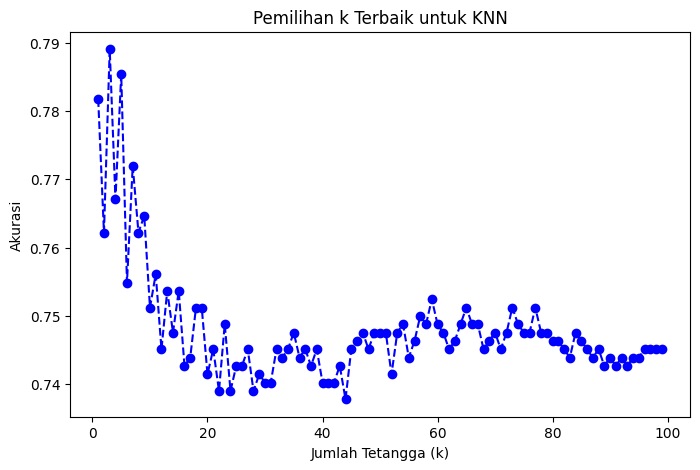

Nilai k terbaik: 3


In [57]:
# Coba beberapa nilai k
k_values = range(1, 100)
scores = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    score = cross_val_score(knn, X_train_smote, y_train_smote, cv=5, scoring='accuracy').mean()
    scores.append(score)

# Plot hasil
plt.figure(figsize=(8,5))
plt.plot(k_values, scores, marker='o', linestyle='dashed', color='blue')
plt.xlabel("Jumlah Tetangga (k)")
plt.ylabel("Akurasi")
plt.title("Pemilihan k Terbaik untuk KNN")
plt.show()

# Nilai k terbaik
best_k = k_values[np.argmax(scores)]
print(f"Nilai k terbaik: {best_k}")

In [58]:
knn = KNeighborsClassifier(n_neighbors=best_k)

param_grid = {
    'weights': ['uniform', 'distance'],  # Cara memberi bobot
    'metric': ['euclidean', 'manhattan', 'minkowski']  # Jenis jarak
}

grid_search = GridSearchCV(knn, param_grid, cv=5, n_jobs=-1, verbose=2, scoring='accuracy')
grid_search.fit(X_train_smote, y_train_smote)

print("Best parameters:", grid_search.best_params_)
print("Best score:", grid_search.best_score_)

Fitting 5 folds for each of 6 candidates, totalling 30 fits
Best parameters: {'metric': 'euclidean', 'weights': 'distance'}
Best score: 0.7987804878048779


In [59]:
lr = LogisticRegression(max_iter=2000, random_state=42)

# Grid hyperparameter
param_grid = {
    'C': [0.01, 0.1, 1, 10, 100],
    'solver': ['liblinear', 'lbfgs']
}

# Grid Search dengan Cross Validation
grid_search = GridSearchCV(lr, param_grid, cv=5, n_jobs=-1, verbose=2, scoring='accuracy')
grid_search.fit(X_train_smote, y_train_smote)

print("Best parameters:", grid_search.best_params_)
print("Best score:", grid_search.best_score_)

Fitting 5 folds for each of 10 candidates, totalling 50 fits
Best parameters: {'C': 0.01, 'solver': 'liblinear'}
Best score: 0.751219512195122


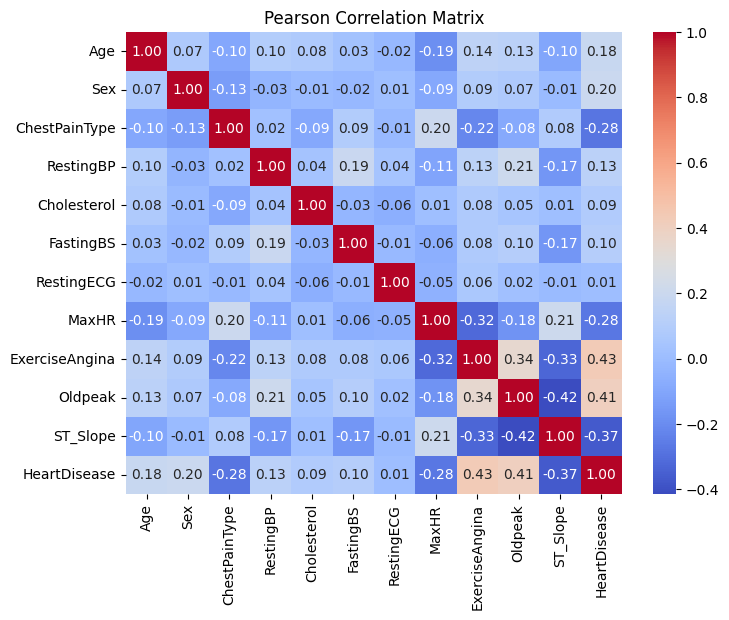

In [60]:
# Pearson
correlation_matrix = df.corr(method='pearson')

# Visualisasi heatmap
plt.figure(figsize=(8,6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Pearson Correlation Matrix")
plt.show()

In [61]:
from scipy.stats import pointbiserialr

# Point-Biserial Correlation
corr, pval = pointbiserialr(df['Oldpeak'], df['HeartDisease'])
print("Point-Biserial correlation:", corr)
print("p-value:", pval)

Point-Biserial correlation: 0.40699881696943513
p-value: 3.3198594752598155e-39


In [62]:
from scipy.stats import chi2_contingency

# Chi-Square
table = pd.crosstab(df['Sex'], df['HeartDisease'])
chi2, p, dof, expected = chi2_contingency(table)
print(f"Chi-Square Statistic: {chi2}")
print(f"P-value: {p}")
print(f"Degrees of Freedom: {dof}")

Chi-Square Statistic: 36.28523774040644
P-value: 1.7045007670196486e-09
Degrees of Freedom: 1


In [63]:
from sklearn.feature_selection import f_classif

# ANOVA
f_values, p_values = f_classif(df[['Oldpeak']], df['HeartDisease'])

anova_df = pd.DataFrame({
    'feature': ['Oldpeak'],
    'F_value': f_values,
    'p_value': p_values
})

print(anova_df)

   feature     F_value       p_value
0  Oldpeak  188.211146  3.319859e-39


In [64]:
# Cramer's V
cramers_v = np.sqrt(chi2 / (table.sum().sum() * (min(table.shape)-1)))
print(f"Cramer's V for Sex and HeartDisease: {cramers_v}")

Cramer's V for Sex and HeartDisease: 0.19574469326740646
